# O-RAN 7.2x Downlink Closed-Loop Simulation: Module-by-Module Walkthrough

This notebook splits the simulation into modules along the signal flow. Each step calls the components in `oran/` directly and plots the intermediate results, so that the complete chain is easy to follow.
`studies/oran_baseline/rt_closed_loop.py` and `studies/oran_baseline/rt_compare_compression.py` do the same thing, but wrap these steps for batch runs and statistics.

```
Physical environment (ray tracing / CDL) → channel
   │
O-DU: precoding (TDD reciprocity, BD computed from CSI)
   │
Measurement slot: CSI-RS + CSI-IM ─ fronthaul (Cat A/B, compression) ─ O-RU ─ channel ─ UE: estimation → CQI → UCI report
   │
MAC: CQI → MCS (+ OLLA)
   │
Data slots: O-DU High-PHY (TB→LDPC→modulation→layer mapping→RE mapping) ─ fronthaul ─ O-RU ─ channel ─ UE: DMRS estimation → LMMSE → decoding → CRC
   │
ACK/NACK → OLLA (next CSI-RS period)
```

| Section | Module | Code |
|---|---|---|
| 0–1 | Switches, initialization | `oran/config.py` |
| 2 | Physical environment and channel | `oran/rt_channel.py`, `oran/channel.py` |
| 3 | Resource grid: PDSCH, DMRS, CSI-RS / CSI-IM | `oran/pdsch.py`, `oran/csi_rs.py` |
| 4 | Precoding (O-DU) | `oran/precoding.py` |
| 5 | Measurement slot and CQI (UE) | `oran/csi_rs.py`, `oran/csi.py`, `oran/bler_model.py` |
| 6 | Link adaptation (MAC) | `oran/link_adaptation.py` |
| 7 | Data slot: O-DU → fronthaul → O-RU → channel → UE | `oran/odu.py`, `oran/fronthaul.py`, `oran/compression/`, `oran/oru.py`, `oran/ue.py`, `oran/channel_estimation.py` |
| 8 | Closed loop (multiple CSI-RS periods) | simplified version of `oran/closed_loop.py` |
| 9 | Cat A/B × compression on the same drop (optional) | simplified version of `studies/oran_baseline/rt_compare_compression.py` |

**Usage**: set the switches in Section 0, then run the notebook from top to bottom ("Run All"). Ray tracing needs a GPU and the user-space libraries of the 580 driver;
the VS Code Jupyter kernel sets `LD_LIBRARY_PATH` automatically through the `.env` file in the project root. With the default settings, the whole notebook takes about 2–3 minutes.

## 0. Switches

All configurable settings are collected here. Notes:

- `CHANNEL_MODEL = "rt"`: UEs are dropped at random in the munich scene, and the SNR follows from the position and the link budget; `"cdl"`: one fixed CDL channel realization (static UE), with the SNR given by `SNR_DB`.
- `CATEGORY`: Cat A precodes in the O-DU and carries antenna-port streams over the fronthaul; Cat B carries layer streams + precoding weights over the fronthaul, and the O-RU precodes.
- `UPLANE` / `BFW`: fronthaul compression method and bit width. `("ideal", 16)` is an ideal fronthaul (no quantization).
- `CQI_SOURCE`: `"csi-rs"` is a real measurement (the CSI-RS goes through the fronthaul, so part of the compression distortion is visible); `"genie"` uses the true effective channel (the fronthaul is not visible).

In [1]:
# ================================ Switches ================================
# ---- Channel ----
CHANNEL_MODEL = "rt"           # "rt": Sionna RT ray tracing (munich); "cdl": 3GPP CDL
TX_POWER_DBM  = 35.0           # rt: total O-RU transmit power [dBm] (20 MHz)
DROP_SEED     = 1              # rt: drop seed; change it to get a different set of UE positions
SNR_DB        = 25.0           # cdl: SNR per receive antenna [dB] (ignored in rt mode)
CDL_MODEL, DELAY_SPREAD = "C", 100e-9   # cdl: CDL model and delay spread [s]

# ---- System ----
CATEGORY      = "A"            # "A": precoding in the O-DU; "B": precoding in the O-RU
NUM_UE        = 2              # 1: SU-MIMO; 2: MU-MIMO (block diagonalization, BD)
LAYERS_PER_UE = 2              # layers per UE: 1, 2, 4
MCS_TABLE     = 2              # 1: up to 64QAM; 2: up to 256QAM (CQI table with the same index)

# ---- Fronthaul compression ----
# Methods: "ideal" (no quantization), "none" (16-bit fixed point), "bfp" (block floating point), "block_scaling", "mu_law" (μ-law)
UPLANE = ("mu_law", 5)            # U-plane IQ
BFW    = ("mu_law", 5)            # Cat B C-plane beamforming weights

# ---- UE receiver and CSI ----
CHANNEL_ESTIMATION = "ls"      # "ls": DMRS LS estimation; "perfect": perfect channel knowledge
DELAY_COMPENSATION = True      # compensate the timing offset before DMRS / CSI-RS estimation
CQI_SOURCE    = "csi-rs"       # "csi-rs": CSI-RS / CSI-IM through the fronthaul; "genie": true effective channel

# ---- Closed loop ----
OLLA             = True        # outer-loop link adaptation
NUM_PERIODS      = 12          # number of CSI-RS periods
SLOTS_PER_PERIOD = 7           # data slots per period (plus 1 measurement slot, i.e. 8 slots per period)
WARMUP_PERIODS   = 3           # initial periods excluded from the statistics (OLLA convergence)

# ---- Optional: Cat A/B × compression on the same drop (about 1–2 minutes) ----
RUN_COMPARISON = True
COMPARE_WIDTHS = [("ideal", 16), ("block_scaling", 5), ("mu_law", 5)]

DEVICE = "cuda:0"
SEED   = 42

## 1. Initialization

Build the simulation configuration `ORANConfig` and the end-to-end link `ORANDownlink` (it contains the O-DU, the fronthaul link of each O-RU, the O-RUs, the channel and the UE receivers).

In [2]:
import os, sys, time, warnings
from dataclasses import replace

ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "oran")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
if "nvidia" not in os.environ.get("LD_LIBRARY_PATH", ""):
    print("Note: LD_LIBRARY_PATH does not contain the 580 driver user-space libraries; ray tracing may not be able to use the GPU (see .env / env.sh)")

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import sionna.phy
from sionna.phy import config as sionna_config

torch.set_grad_enabled(False)

from oran import ORANConfig, ORANDownlink, CompressionConfig
from oran.channel import ChannelState
from oran.precoding import apply_precoder, effective_channel
from oran.csi_rs import CSIRS, CSIRSReceiver
from oran.csi import CQIReporter, lmmse_sinr, reference_data_symbols, reference_num_re
from oran.bler_model import AWGNLinkModel, mcs_entry
from oran.link_adaptation import LinkAdaptation, LinkAdaptationConfig
from oran.fronthaul import fronthaul_rate

sionna_config.device = DEVICE
sionna_config.seed = SEED
db = lambda x: 10 * np.log10(np.maximum(np.asarray(x, dtype=float), 1e-30))

cfg = ORANConfig(channel_model=CHANNEL_MODEL, category=CATEGORY, num_ue=NUM_UE,
                 num_layers_per_ue=LAYERS_PER_UE, mcs_table=MCS_TABLE,
                 uplane=CompressionConfig(*UPLANE), bfw=CompressionConfig(*BFW),
                 channel_estimation=CHANNEL_ESTIMATION, ce_delay_compensation=DELAY_COMPENSATION,
                 cqi_source=CQI_SOURCE, cdl_model=CDL_MODEL, delay_spread=DELAY_SPREAD, device=DEVICE)
cfg.rt.tx_power_dbm = TX_POWER_DBM

t0 = time.time()
sim = ORANDownlink(cfg)
print(f"Initialization {time.time() - t0:.1f} s")
print(f"Carrier: {cfg.subcarrier_spacing} kHz SCS, {cfg.num_prb} PRB ({cfg.num_subcarriers} subcarriers), "
      f"{cfg.carrier_frequency / 1e9:.1f} GHz, {cfg.slots_per_second} slots per second")
print(f"Nodes: {cfg.num_oru} O-RU × {cfg.num_oru_ant} TX chains; {cfg.num_ue} UE × {cfg.num_ue_ant} antennas, "
      f"{cfg.num_layers_per_ue} layers per UE ({cfg.num_layers} layers in total)")
print(f"Cat {cfg.category}; U-plane {cfg.uplane.method} {cfg.uplane.iq_width} bit; "
      f"weights {cfg.bfw.method} {cfg.bfw.iq_width} bit (Cat B only); precoder {cfg.precoder.upper()}, PRG {cfg.prg_size} PRB")
print(f"Channel: {CHANNEL_MODEL}; UE channel estimation: {cfg.channel_estimation}; CQI source: {cfg.cqi_source}")

Initialization 4.8 s
Carrier: 30 kHz SCS, 51 PRB (612 subcarriers), 3.5 GHz, 2000 slots per second
Nodes: 1 O-RU × 8 TX chains; 2 UE × 4 antennas, 2 layers per UE (4 layers in total)
Cat A; U-plane mu_law 5 bit; weights mu_law 5 bit (Cat B only); precoder BD, PRG 2 PRB
Channel: rt; UE channel estimation: ls; CQI source: csi-rs


## 2. Physical environment and channel

**Ray tracing (`rt`)**: the map-based hybrid model of TR 38.901 §8. The O-RU is mounted on the roof of a 26 m tall building in the munich scene (4 m mast), with the sector facing north.
UEs are dropped uniformly at random in the coverage area (outdoor, 1.5 m height, static). Ray tracing gives the multipath components (amplitude, delay) of every (UE, O-RU) link.
The channel is scaled by $\sqrt{P_{RE}/N_0}$ so that the noise variance is 1; the SNR is therefore determined by the position.

**CDL (`cdl`)**: one fixed CDL channel realization (static UE), noise variance $10^{-\mathrm{SNR}/10}$.

UE0: position (  86.0,  -13.7) m, path gain -101.1 dB, wideband SNR  26.2 dB (per receive antenna, without beamforming gain), 44 paths
UE1: position ( -53.9,  -18.9) m, path gain  -98.5 dB, wideband SNR  28.8 dB (per receive antenna, without beamforming gain), 34 paths


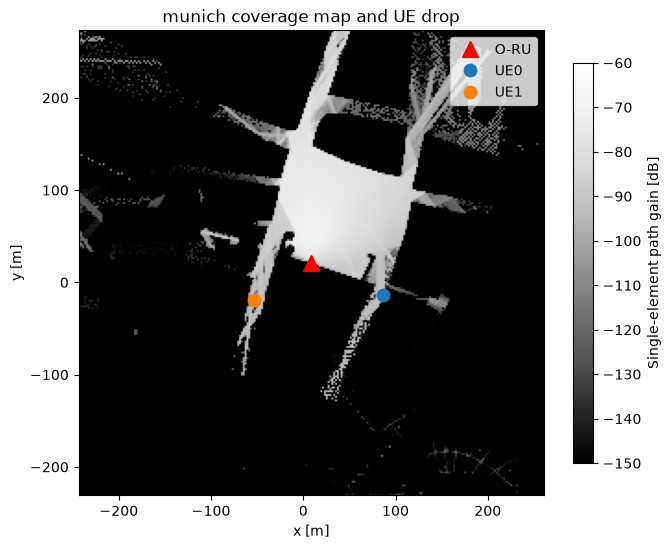

In [3]:
if CHANNEL_MODEL == "rt":
    rt = sim.channel.model                    # oran.rt_channel.RTChannel
    scene = rt.scene                          # oran.rt_channel.RTScene
    positions = scene.drop_ues(NUM_UE, DROP_SEED)
    sim.channel.set_ue_positions(positions)   # ray tracing → frequency-domain channel (incl. link budget)
    for k in range(NUM_UE):
        print(f"UE{k}: position ({positions[k, 0]:6.1f}, {positions[k, 1]:6.1f}) m, path gain {rt.path_gain_db()[k]:6.1f} dB, "
              f"wideband SNR {rt.wideband_snr_db()[k]:5.1f} dB (per receive antenna, without beamforming gain), {rt.num_paths[k].sum()} paths")

    # Coverage map (single-element pattern, no refraction; used for the drop) and UE positions
    rm = scene.coverage_map()
    cc = rm.cell_centers.numpy()
    cell = cfg.rt.coverage_cell_size
    pg = db(rm.path_gain.numpy().max(axis=0))
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(pg, origin="lower", cmap="Greys_r", vmin=-150, vmax=-60,
                   extent=[cc[0, 0, 0] - cell / 2, cc[-1, -1, 0] + cell / 2, cc[0, 0, 1] - cell / 2, cc[-1, -1, 1] + cell / 2])
    fig.colorbar(im, ax=ax, label="Single-element path gain [dB]", shrink=0.8)
    oru = np.array(cfg.rt.oru_positions[0])
    ax.plot(oru[0], oru[1], "r^", ms=12, label="O-RU")
    for k in range(NUM_UE):
        ax.plot(positions[k, 0], positions[k, 1], "o", ms=9, label=f"UE{k}")
    ax.legend(); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_title("munich coverage map and UE drop")
    plt.show()
else:
    state0 = sim.channel.sample(1)            # fixed CDL channel realization
    print(f"CDL-{CDL_MODEL}, delay spread {DELAY_SPREAD * 1e9:.0f} ns, SNR {SNR_DB} dB")

SNR_RUN = 0.0 if CHANNEL_MODEL == "rt" else SNR_DB   # SNR argument of run_batch / measurement_slot
NO = 10 ** (-SNR_RUN / 10)                             # noise variance (1 in rt mode)


def make_state(batch_size, sim_=None):
    # batch_size consecutive slots of the same channel realization (static UE)
    s = sim_ or sim
    if CHANNEL_MODEL == "rt":
        return s.channel.sample(batch_size)
    h = state0.h_freq
    return ChannelState(h.expand(batch_size, *h.shape[1:]))

3D scene and propagation paths (rendered with Sionna RT; the red sphere is the O-RU, the green spheres are the UEs, and the lines are propagation paths):

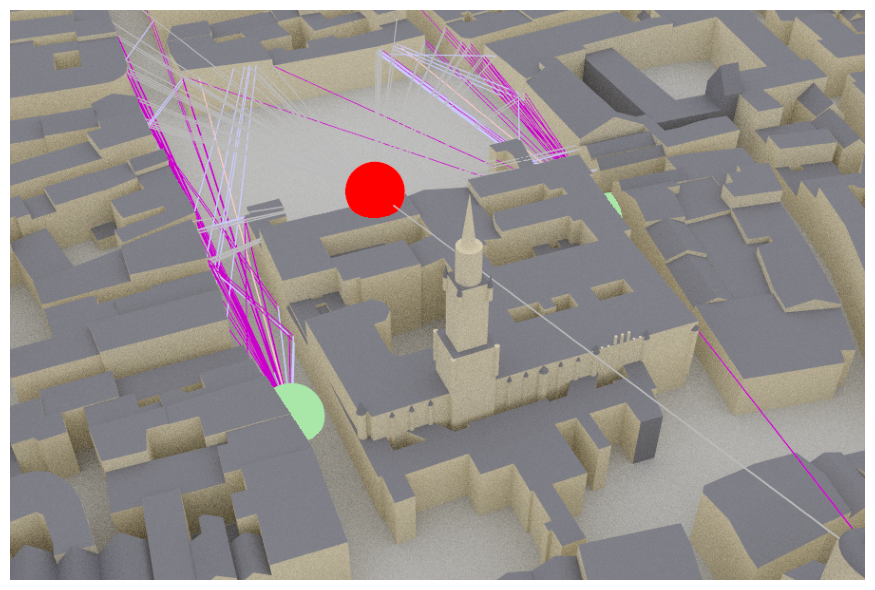

In [4]:
if CHANNEL_MODEL == "rt":
    from sionna.rt import Camera
    paths = scene.solver(scene.scene, max_depth=cfg.rt.max_depth, diffraction=cfg.rt.diffraction,
                         synthetic_array=True)
    center = np.vstack([positions, oru[None]]).mean(axis=0)
    cam = Camera(position=[float(oru[0] - 160), float(oru[1] - 220), 220.0],
                 look_at=[float(center[0]), float(center[1]), 0.0])
    fig = scene.scene.render(camera=cam, paths=paths, resolution=[900, 600], num_samples=64)
    plt.show()

Power delay profile (power of each path, averaged over all antennas) and frequency response (one TX/RX antenna pair). The larger the delay spread, the faster the response fluctuates over frequency.
Each UE takes the earliest-arriving path as its timing reference, so a weak first path followed by late strong paths produces a pronounced linear phase (see the timing-offset compensation in Section 7).

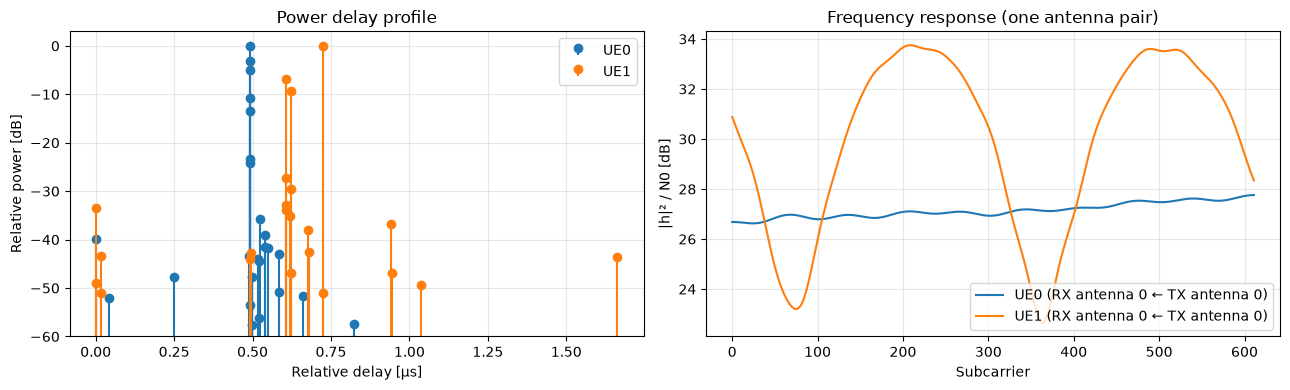

In [5]:
if CHANNEL_MODEL == "rt":
    a, tau = scene.cir()                                  # a: [K, N_r, O-RU, N_TRX, path], tau: [K, O-RU, path]
    p = (a.abs() ** 2).mean(dim=(1, 3))                   # [K, O-RU, path]
else:
    a, tau = sim.channel.model(1, 1, 1.0)                 # CDL: [1, K, N_r, O-RU, N_TRX, path, 1]
    a, tau = a[0, ..., 0], tau[0]
    p = (a.abs() ** 2).mean(dim=(1, 3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k in range(NUM_UE):
    t, pk = tau[k, 0].cpu().numpy(), p[k, 0].cpu().numpy()
    valid = (t >= 0) & (pk > 0)
    t, pk = t[valid] - t[valid].min(), pk[valid]
    rel = db(pk / pk.max())
    keep = rel > -60
    axes[0].stem(t[keep] * 1e6, rel[keep], linefmt=f"C{k}-", markerfmt=f"C{k}o", basefmt=" ", bottom=-60,
                 label=f"UE{k}")
axes[0].set_ylim(-60, 3); axes[0].set_xlabel("Relative delay [µs]"); axes[0].set_ylabel("Relative power [dB]")
axes[0].set_title("Power delay profile"); axes[0].legend(); axes[0].grid(alpha=0.3)
h = make_state(1).h_freq                                  # [1, K, N_r, O-RU, N_TRX, symbol, subcarrier]
for k in range(NUM_UE):
    axes[1].plot(db(h[0, k, 0, 0, 0, 3].abs().cpu().numpy() ** 2 / NO), label=f"UE{k} (RX antenna 0 ← TX antenna 0)")
axes[1].set_xlabel("Subcarrier"); axes[1].set_ylabel("|h|² / N0 [dB]"); axes[1].set_title("Frequency response (one antenna pair)")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. Resource grid: PDSCH, DMRS, CSI-RS / CSI-IM

- **Data slot**: all 14 symbols are allocated to the PDSCH; DMRS Type 1 on symbols 2 and 11. The layers of each UE use different DMRS ports; with MU, neither CDM group carries data.
- **Measurement slot** (the first slot of each CSI-RS period): symbol 12 carries one precoded NZP CSI-RS per UE (channel measurement resource, CMR;
  with 2 ports this is row 3 of TS 38.211 Table 7.4.1.5.3-1, fd-CDM2) and a CSI-IM (pattern1, 4 subcarriers). The PDSCH is punctured on these REs.
  The CMR of the paired UE also serves as this UE's interference measurement resource (NZP-IMR).

UE0: RNTI 100, DMRS ports [0, 1] (CDM groups [0, 0]), DMRS symbols [2, 11], CDM groups without data 2
UE1: RNTI 101, DMRS ports [2, 3] (CDM groups [1, 1]), DMRS symbols [2, 11], CDM groups without data 2
Data REs per layer: 7344 (one slot)
CSI-RS: Table 7.4.1.5.3-1 row 3, CDM length 2, symbol 12, CSI-IM starting subcarrier 4, 8 REs per PRB


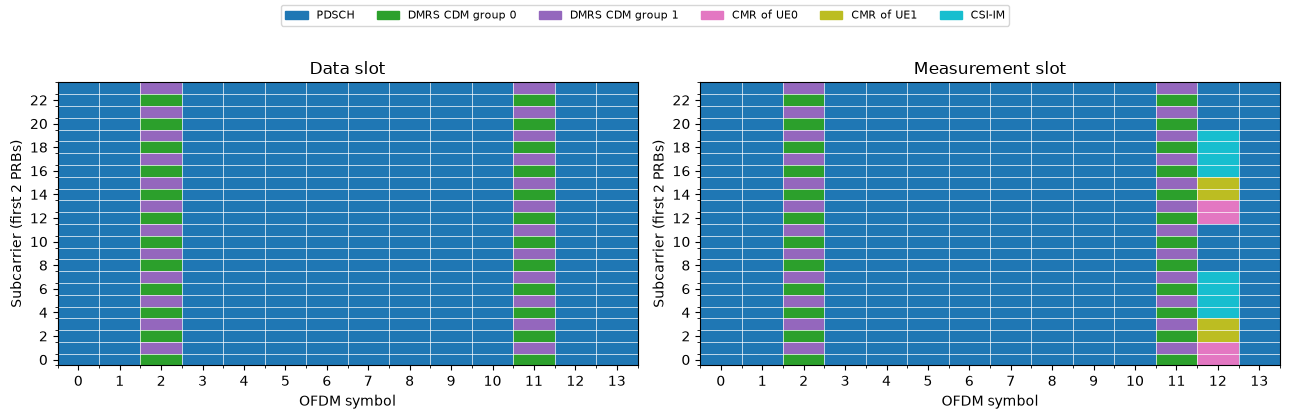

In [6]:
for k, pc in enumerate(sim.pdsch_configs):
    print(f"UE{k}: RNTI {pc.n_rnti}, DMRS ports {pc.dmrs.dmrs_port_set} (CDM groups {list(pc.dmrs.cdm_groups)}), "
          f"DMRS symbols {list(pc.dmrs_symbol_indices)}, CDM groups without data {pc.dmrs.num_cdm_groups_without_data}")
print(f"Data REs per layer: {sim.rg.num_data_symbols} (one slot)")

csirs = CSIRS(cfg, sim.pdsch_configs[0], device=DEVICE)
print(f"CSI-RS: Table 7.4.1.5.3-1 row {csirs.row}, CDM length {csirs.cdm}, symbol {csirs.symbol}, "
      f"CSI-IM starting subcarrier {csirs.im_offset}, {csirs.overhead_re_per_prb} REs per PRB")

# Plot the first 2 PRBs: 0 PDSCH, 1/2 DMRS (CDM group 0/1), 3+k CMR of UE k, last class CSI-IM
F = 24
pp = sim.rg.pilot_pattern
mask = pp.mask.cpu().numpy().astype(bool)                 # [UE, layer, symbol, subcarrier]
pil = pp.pilots.cpu().numpy()                             # [UE, layer, pilot]
data_grid = np.zeros((14, F), int)
for t in range(mask.shape[0]):
    for s in range(mask.shape[1]):
        pos = np.argwhere(mask[t, s])
        nz = np.abs(pil[t, s]) > 0
        group = sim.pdsch_configs[t].dmrs.cdm_groups[s]
        for l, kk in pos[nz]:
            if kk < F:
                data_grid[l, kk] = 1 + group
meas_grid = data_grid.copy()
for k in range(NUM_UE):
    sc = csirs.cmr_sc[k].reshape(-1)
    meas_grid[csirs.symbol, sc[sc < F]] = 3 + k
im_cls = 3 + NUM_UE
meas_grid[csirs.symbol, csirs.im_sc.reshape(-1)[csirs.im_sc.reshape(-1) < F]] = im_cls

names = ["PDSCH", "DMRS CDM group 0", "DMRS CDM group 1"] + [f"CMR of UE{k}" for k in range(NUM_UE)] + ["CSI-IM"]
cmap = plt.get_cmap("tab10", len(names))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, g, title in ((axes[0], data_grid, "Data slot"), (axes[1], meas_grid, "Measurement slot")):
    ax.imshow(g.T, origin="lower", cmap=cmap, vmin=-0.5, vmax=len(names) - 0.5, aspect="auto")
    ax.set_xlabel("OFDM symbol"); ax.set_ylabel("Subcarrier (first 2 PRBs)"); ax.set_title(title)
    ax.set_xticks(range(14)); ax.set_yticks(range(0, F, 2))
    ax.set_xticks(np.arange(-0.5, 14), minor=True); ax.set_yticks(np.arange(-0.5, F), minor=True)
    ax.grid(which="minor", color="w", lw=0.5)
fig.legend(handles=[Patch(color=cmap(i), label=n) for i, n in enumerate(names)], loc="upper center",
           ncol=len(names), fontsize=8)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

## 4. Precoding (O-DU)

TDD reciprocity: the O-DU obtains the downlink channel from the SRS (assumed ideal here) and computes a block-diagonalization (BD) precoder $W$ at the center subcarrier of each PRG (2 PRBs),
so that the layers of UE k fall into the null space of the other UEs' channels. $\|W\|_F = 1$, with equal power per layer.
In Cat A the O-DU precodes with $W$ directly; in Cat B, $W$ is sent to the O-RU over the C-plane (optionally compressed).

Left: power of each layer received by each UE (relative to the noise). The diagonal blocks are the UE's own layers; the off-diagonal blocks are the residual interference after BD nulling.
Right: power of UE0's own layers and of the paired UE's layers at UE0, versus subcarrier. BD nulls exactly only at the center subcarrier of each PRG, so the channel variation within a PRG leaves residual interference.

CSI (1, 26, 2, 4, 8) → precoder W (1, 26, 8, 4), ||W||_F² = 1.000


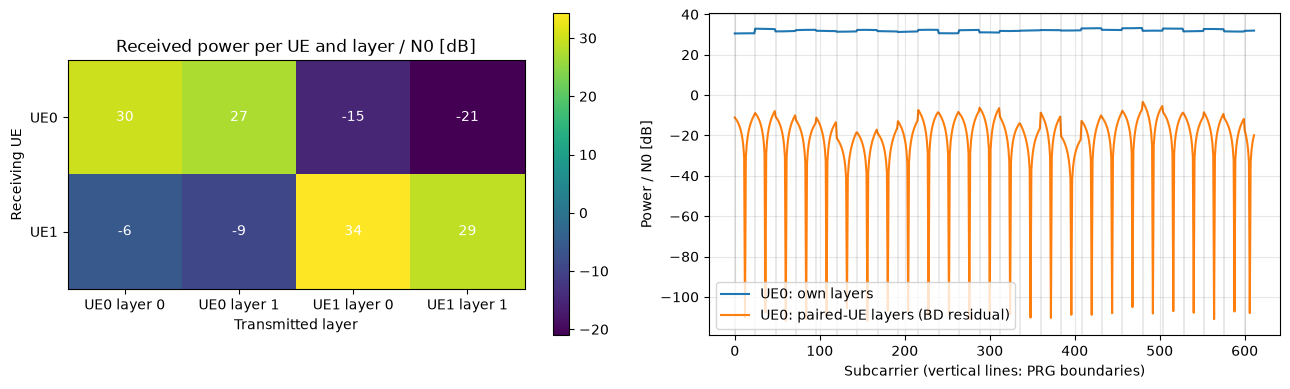

In [7]:
state = make_state(1)
h_csi = sim.channel.csi(state, sim.csi_symbol)             # [1, PRG, K, N_r, N_t]
w = sim.odu.precoder(h_csi)                                # [1, PRG, N_t, L]
print(f"CSI {tuple(h_csi.shape)} → precoder W {tuple(w.shape)}, ||W||_F² = {float((w.abs() ** 2).sum((-1, -2)).mean()):.3f}")

g = effective_channel(state.stacked(), w, sim.odu.prg_of_sc)   # effective channel H·W: [1, K, N_r, L, symbol, subcarrier]
p = (g.abs() ** 2)[0, :, :, :, 3, :].sum(dim=1)                 # power of each layer at each UE (summed over RX antennas) [K, L, F]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pm = db(p.mean(-1).cpu().numpy() / NO)
im = axes[0].imshow(pm, cmap="viridis")
for i in range(pm.shape[0]):
    for j in range(pm.shape[1]):
        axes[0].text(j, i, f"{pm[i, j]:.0f}", ha="center", va="center", color="w")
axes[0].set_xticks(range(pm.shape[1]))
axes[0].set_xticklabels([f"UE{l // LAYERS_PER_UE} layer {l % LAYERS_PER_UE}" for l in range(pm.shape[1])])
axes[0].set_yticks(range(pm.shape[0])); axes[0].set_yticklabels([f"UE{k}" for k in range(pm.shape[0])])
axes[0].set_xlabel("Transmitted layer"); axes[0].set_ylabel("Receiving UE"); axes[0].set_title("Received power per UE and layer / N0 [dB]")
fig.colorbar(im, ax=axes[0])
nu = LAYERS_PER_UE
axes[1].plot(db(p[0, :nu].sum(0).cpu().numpy() / NO), label="UE0: own layers")
if NUM_UE > 1:
    axes[1].plot(db(p[0, nu:].sum(0).cpu().numpy() / NO), label="UE0: paired-UE layers (BD residual)")
for b in range(0, cfg.num_subcarriers, 12 * cfg.prg_num_prb):
    axes[1].axvline(b, color="k", lw=0.3, alpha=0.4)
axes[1].set_xlabel("Subcarrier (vertical lines: PRG boundaries)"); axes[1].set_ylabel("Power / N0 [dB]"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Measurement slot and CQI (UE)

In the measurement slot, the CSI-RS / CSI-IM go together with the PDSCH through the fronthaul (Cat A/B, compression), the O-RU and the channel to the UE (`ORANDownlink.measurement_slot`). On the UE side (`CSIRSReceiver`):

1. compensate the timing with the phase slope estimated from the PDSCH DMRS;
2. in each PRB, LS estimation on the 2 CMR REs + CDM2 despreading gives the effective channel of each port (layer) of this UE;
3. the mean power on the CSI-IM is taken as the noise variance (**REs that are zero remain zero after compression, so compression distortion is not measured here**);
4. the paired UE's CMR (NZP-IMR) gives the multi-user interference covariance (with the estimation noise removed);
5. LMMSE SINR per PRB and layer → EESM effective SINR → the largest CQI with TBLER ≤ 0.1 (TS 38.214 §5.2.2.1, CSI reference resource according to §5.2.2.5.1).

For comparison, the "genie" CQI is computed directly from the true effective channel, bypassing the fronthaul.

UE0: noise measured on CSI-IM   0.20 dB (true   0.00 dB), INR measured on NZP-IMR  -0.3 dB
     CSI-RS: effective SINR  25.0 dB → CQI 14   |   genie: effective SINR  27.9 dB → CQI 15
UE1: noise measured on CSI-IM   0.05 dB (true   0.00 dB), INR measured on NZP-IMR   1.7 dB
     CSI-RS: effective SINR  23.1 dB → CQI 13   |   genie: effective SINR  24.8 dB → CQI 14


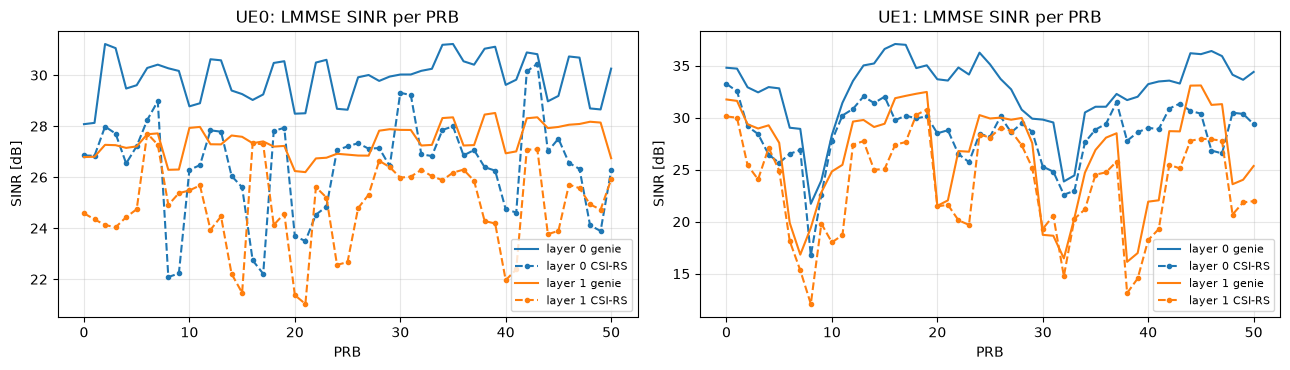

In [8]:
model = AWGNLinkModel(0.1, device=DEVICE)                  # AWGN link abstraction: TBLER thresholds and EESM for each (Qm, R)
pc0 = sim.pdsch_configs[0]
REF_SYMBOLS = reference_data_symbols(pc0)                  # data symbols of the CSI reference resource
reporter = CQIReporter(MCS_TABLE, reference_num_re(pc0, cfg.num_prb, LAYERS_PER_UE), model)


def genie_cqi(sim_, state_):
    h_ = state_.stacked()[:1][..., REF_SYMBOLS, :]
    w_ = sim_.odu.precoder(sim_.channel.csi(state_, sim_.csi_symbol)[:1])
    sinr = lmmse_sinr(h_, w_, NO, sim_.odu.prg_of_sc, LAYERS_PER_UE)[0]     # [K, ν, symbol, subcarrier]
    return reporter(sinr), sinr


def csirs_cqi(sim_, state_, csi_rx_):
    y_ = sim_.measurement_slot(state_, SNR_RUN, csirs)                      # measurement slot reaches the UE through the fronthaul
    sinr, diag = csi_rx_.sinr(y_)                                           # [1, K, ν, PRB]
    return reporter(sinr[0]), sinr[0], diag


csi_rx = CSIRSReceiver(csirs, cfg.prg_num_prb, sim.ue.estimator)
state = make_state(1)
(cqi_g, eff_g), sinr_g = genie_cqi(sim, state)
(cqi_r, eff_r), sinr_r, diag = csirs_cqi(sim, state, csi_rx)
for k in range(NUM_UE):
    inr = f", INR measured on NZP-IMR {db(diag['inr'][0, k].item()):5.1f} dB" if NUM_UE > 1 else ""
    print(f"UE{k}: noise measured on CSI-IM {db(diag['noise'][0, k].item()):6.2f} dB (true {db(NO):6.2f} dB){inr}")
    print(f"     CSI-RS: effective SINR {eff_r[k]:5.1f} dB → CQI {cqi_r[k]:2d}   |   genie: effective SINR {eff_g[k]:5.1f} dB → CQI {cqi_g[k]:2d}")

fig, axes = plt.subplots(1, NUM_UE, figsize=(6.5 * NUM_UE, 3.8), squeeze=False)
for k in range(NUM_UE):
    ax = axes[0, k]
    for l in range(LAYERS_PER_UE):
        gl = sinr_g[k, l].mean(0).reshape(cfg.num_prb, 12).mean(-1).cpu().numpy()   # genie: averaged per PRB
        ax.plot(db(gl), f"C{l}-", label=f"layer {l} genie")
        ax.plot(db(sinr_r[k, l].cpu().numpy()), f"C{l}--", marker=".", label=f"layer {l} CSI-RS")
    ax.set_xlabel("PRB"); ax.set_ylabel("SINR [dB]"); ax.set_title(f"UE{k}: LMMSE SINR per PRB")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Link adaptation (MAC)

3GPP does not specify how the gNB uses the CQI. The approach used here (`LinkAdaptation`): CQI → threshold SINR of that CQI (a conservative lower bound) → add the OLLA offset →
select the largest MCS whose threshold does not exceed this value (the MCS thresholds are computed for the actual PDSCH allocation). OLLA: each ACK changes the offset by +δ·p/(1−p) and each NACK by −δ,
so that the first-transmission BLER converges to p = 0.1.

Sionna's LDPC encoder does not support repetition coding, so MCSs with very low code rates cannot be realized. `supported_mcs()` tries to build the coding chain for each MCS to find the usable ones (about 10 s).

Usable MCS: [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27] (8.9 s)


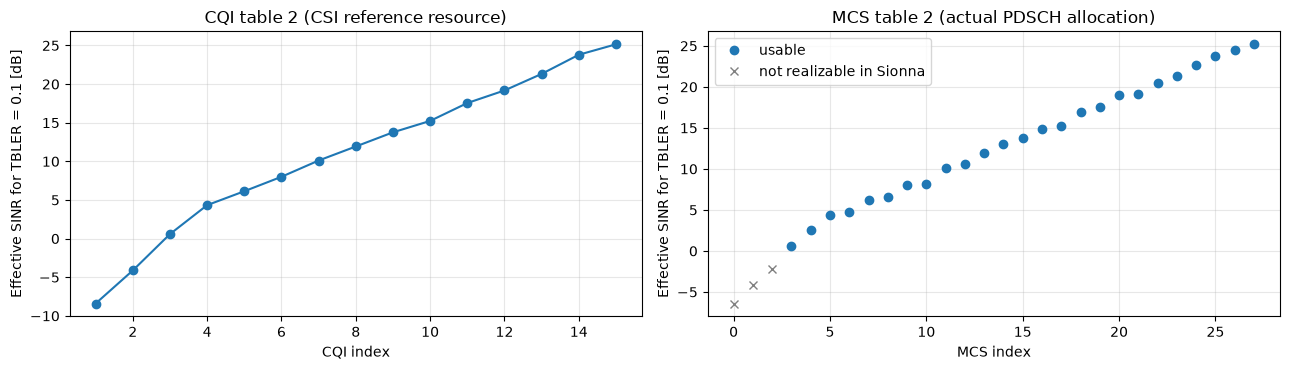

UE0: CQI 14 → SINR estimate  23.8 dB (incl. OLLA offset +0.0 dB) → MCS 25 (256QAM, R = 885/1024) → TBS 102416 bit
UE1: CQI 13 → SINR estimate  21.3 dB (incl. OLLA offset +0.0 dB) → MCS 22 (256QAM, R = 754/1024) → TBS 86040 bit


In [9]:
t0 = time.time()
allowed = sim.supported_mcs()
la = LinkAdaptation(LinkAdaptationConfig(olla=OLLA), MCS_TABLE, NUM_UE,
                    sim.rg.num_data_symbols * LAYERS_PER_UE, reporter, model, allowed)
print(f"Usable MCS: {allowed} ({time.time() - t0:.1f} s)")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(range(1, 16), reporter.threshold_db, "o-")
axes[0].set_xlabel("CQI index"); axes[0].set_ylabel("Effective SINR for TBLER = 0.1 [dB]")
axes[0].set_title(f"CQI table {MCS_TABLE} (CSI reference resource)"); axes[0].grid(alpha=0.3)
ok = np.isin(np.arange(len(la.mcs_threshold_db)), allowed)
axes[1].plot(np.flatnonzero(ok), la.mcs_threshold_db[ok], "o", label="usable")
axes[1].plot(np.flatnonzero(~ok), la.mcs_threshold_db[~ok], "x", color="gray", label="not realizable in Sionna")
axes[1].set_xlabel("MCS index"); axes[1].set_ylabel("Effective SINR for TBLER = 0.1 [dB]")
axes[1].set_title(f"MCS table {MCS_TABLE} (actual PDSCH allocation)"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

cqi = cqi_r if CQI_SOURCE == "csi-rs" else cqi_g
mcs = la.select_mcs(cqi)
sim.set_mcs(mcs)                                           # switch the O-DU coding chain and the UE decoding chain to the new MCS (cached per MCS)
for k in range(NUM_UE):
    qm, r = mcs_entry(MCS_TABLE, int(mcs[k]))
    print(f"UE{k}: CQI {cqi[k]} → SINR estimate {la.sinr_estimate_db(cqi)[k]:5.1f} dB (incl. OLLA offset {la.offset_db[k]:+.1f} dB)"
          f" → MCS {mcs[k]} ({2 ** qm}QAM, R = {r:.0f}/1024) → TBS {sim.tb_sizes[k]} bit")

## 7. Data slots: the PDSCH, module by module

One batch = `SLOTS_PER_PERIOD` consecutive slots on the same channel (same MCS). Below, `ORANDownlink.run_batch` is taken apart and executed step by step.

### 7.1 O-DU High-PHY

TB CRC → code block segmentation + CB CRC → LDPC → rate matching → scrambling (`TBEncoder`, TS 38.212 §7.2) → QAM modulation → layer mapping → RE mapping (data + DMRS);
in Cat A, this is followed by per-PRG precoding.

UE0 coding chain: info bits 102416 → 13 code blocks (7904 bit each, incl. CB CRC) → LDPC + rate matching → coded bits 117504 (code rate 0.872) → 8 bit/symbol → QAM symbols 14688 → layer mapping (2, 7344)
Layer resource grid x_layers (7, 4, 14, 612) (batch, layer, symbol, subcarrier)
U-plane sent to the O-RU (7, 8, 14, 612): Cat A, precoded antenna-port streams


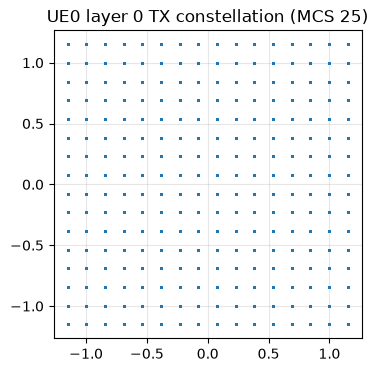

In [10]:
B = SLOTS_PER_PERIOD
state = make_state(B)
h_csi = sim.channel.csi(state, sim.csi_symbol)

enc, mapper, lmap = sim.odu.tb_encoders[0], sim.odu.mappers[0], sim.odu.layer_mappers[0]
b = sim.odu.binary_source([1, 1, enc.tb_size])
c = enc(b)
s = mapper(c)
xl = lmap(s)
print(f"UE0 coding chain: info bits {enc.tb_size} → {enc.num_cbs} code blocks ({enc.ldpc_encoder.k} bit each, incl. CB CRC) → LDPC + rate matching → "
      f"coded bits {c.shape[-1]} (code rate {enc.coderate:.3f}) → {mapper.constellation.num_bits_per_symbol} bit/symbol → "
      f"QAM symbols {s.shape[-1]} → layer mapping {tuple(xl.shape[-2:])}")

tx = sim.odu(B, h_csi)                                     # the whole O-DU (all UEs, B slots)
print(f"Layer resource grid x_layers {tuple(tx.x_layers.shape)} (batch, layer, symbol, subcarrier)")
print(f"U-plane sent to the O-RU {tuple(tx.uplane[0].shape)}: "
      + ("Cat A, precoded antenna-port streams" if CATEGORY == "A" else f"Cat B, layer streams; C-plane weights {tuple(tx.weights[0].shape)}"))

fig, ax = plt.subplots(figsize=(4, 4))
x0 = tx.x_data[0, 0, 0].cpu().numpy()
ax.plot(x0.real, x0.imag, ".", ms=2); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_title(f"UE0 layer 0 TX constellation (MCS {mcs[0]})"); plt.show()

### 7.2 Fronthaul (O-RAN 7.2x U-plane / C-plane)

U-plane: 16-bit fixed point → block compression per PRB (12 REs) (O-RAN WG4 CUS, Annex A) → transport → decompression.
In Cat B, the C-plane beamforming weights are compressed per PRB bundle (Section Extension 11).
The table below lists the fronthaul bit rate of a single O-RU link at 100 MHz (273 PRBs), including eCPRI and Ethernet overhead.

U-plane: mu_law 5 bit, SQNR 25.0 dB, 0 values clipped

Fronthaul bit rate (100 MHz, single O-RU):
          ideal 16 bit: Cat A  24.57 Gbps, Cat B  12.59 Gbps
            bfp  9 bit: Cat A  14.35 Gbps, Cat B   7.36 Gbps
            bfp  7 bit: Cat A  11.31 Gbps, Cat B   5.81 Gbps
            bfp  5 bit: Cat A   8.16 Gbps, Cat B   4.20 Gbps
  block_scaling  7 bit: Cat A  11.31 Gbps, Cat B   5.81 Gbps
         mu_law  7 bit: Cat A  11.31 Gbps, Cat B   5.81 Gbps


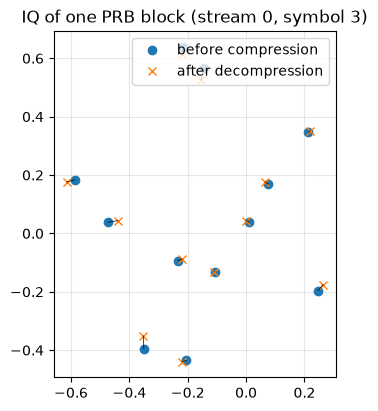

In [11]:
fh = sim.fronthaul[0]
fh.reset_stats()
uplane_hat, w_hat = fh.transmit(tx.uplane[0], tx.weights[0])
print(f"U-plane: {cfg.uplane.method} {cfg.uplane.iq_width} bit, SQNR {fh.uplane.stats.sqnr_db:.1f} dB, "
      f"{fh.uplane.stats.num_clipped} values clipped")
if w_hat is not None:
    print(f"C-plane weights: {cfg.bfw.method} {cfg.bfw.iq_width} bit, SQNR {fh.bfw.stats.sqnr_db:.1f} dB")

print("\nFronthaul bit rate (100 MHz, single O-RU):")
for comp in [("ideal", 16), ("bfp", 9), ("bfp", 7), ("bfp", 5), ("block_scaling", 7), ("mu_law", 7)]:
    rates = [fronthaul_rate(replace(cfg, category=cat, uplane=CompressionConfig(*comp), bfw=CompressionConfig(*comp)),
                            num_prb=273).total / 1e9 for cat in ("A", "B")]
    print(f"  {comp[0]:>13} {comp[1]:2d} bit: Cat A {rates[0]:6.2f} Gbps, Cat B {rates[1]:6.2f} Gbps")

# IQ of one compression block (stream 0, symbol 3, PRB 0) before and after compression
blk, blk_hat = tx.uplane[0][0, 0, 3, :12].cpu().numpy(), uplane_hat[0, 0, 3, :12].cpu().numpy()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(blk.real, blk.imag, "o", label="before compression")
ax.plot(blk_hat.real, blk_hat.imag, "x", label="after decompression")
for u, v in zip(blk, blk_hat):
    ax.plot([u.real, v.real], [u.imag, v.imag], "k-", lw=0.5)
ax.set_aspect("equal"); ax.legend(); ax.grid(alpha=0.3); ax.set_title("IQ of one PRB block (stream 0, symbol 3)")
plt.show()

### 7.3 O-RU

Cat B: per-RE precoding with the (decompressed) weights received over the C-plane; Cat A: pass-through. Then (in time-domain simulation) IFFT + CP.
The transmit EVM reflects only the fronthaul distortion: it is the error of the signal at the O-RU antenna ports relative to an "ideal fronthaul" (no compression, unquantized weights).

In [12]:
oru = sim.orus[0]
grid = oru.frequency_domain(uplane_hat, w_hat)             # frequency-domain grid per antenna [B, N_TRX, symbol, subcarrier]
ideal = apply_precoder(tx.x_layers, tx.w, sim.odu.prg_of_sc)
tx_evm = float(((grid - ideal).abs() ** 2).sum() / (ideal.abs() ** 2).sum()) ** 0.5
print(f"O-RU antenna ports {tuple(grid.shape)}, TX EVM {100 * tx_evm:.2f} % ({db(tx_evm ** 2):.1f} dB)")
x_air = oru.to_air(grid)

O-RU antenna ports (7, 8, 14, 612), TX EVM 5.61 % (-25.0 dB)


### 7.4 Channel and UE receiver

$y = H x + n$, followed at the UE by: DMRS channel estimation (timing-offset compensation + LS + CDM separation and interpolation within each PRG) → LMMSE equalization (with the paired UE's layers whitened as interference)
→ soft demapping → layer demapping → descrambling / rate recovery / LDPC decoding → CRC.

UE0: DMRS channel estimation NMSE  -26.7 dB
UE1: DMRS channel estimation NMSE  -27.7 dB
UE0: MCS 25, CRC over 7 slots [0, 0, 0, 0, 0, 0, 0], BLER 1.00, post-equalization SINR  21.6 dB (EVM 8.33 %)
UE1: MCS 22, CRC over 7 slots [0, 1, 1, 1, 0, 0, 0], BLER 0.57, post-equalization SINR  18.6 dB (EVM 11.69 %)


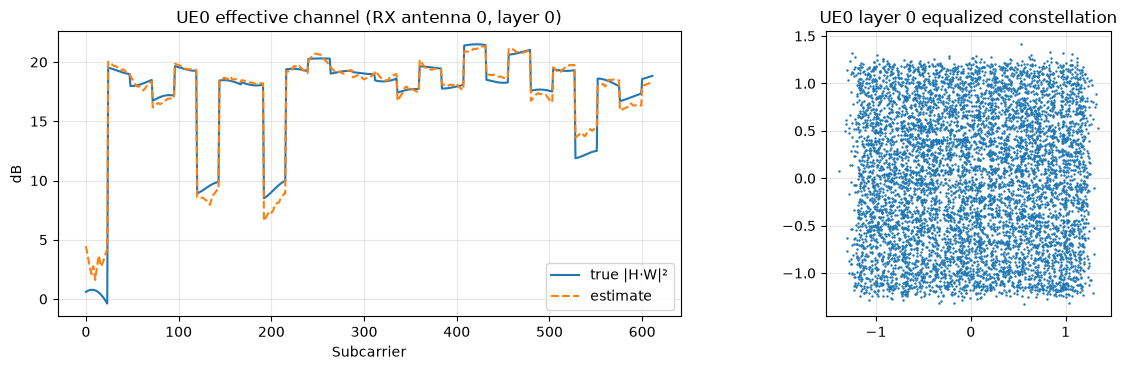

In [13]:
y = sim.channel(x_air[:, None], state, NO)                 # [B, K, N_r, symbol, subcarrier]
y_grid = sim.ue.frequency_grid(y)
w_applied = w_hat if w_hat is not None else tx.w           # weights actually applied by the O-RU
h_true = effective_channel(state.stacked(), w_applied, sim.odu.prg_of_sc).unflatten(3, (NUM_UE, LAYERS_PER_UE))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
if sim.ue.estimator is not None:
    h_hat, err_var = sim.ue.estimator(y_grid, torch.tensor(NO, device=y.device))   # [B, K, N_r, K, ν, symbol, subcarrier]
    for k in range(NUM_UE):
        e = (h_hat[:, k, :, k] - h_true[:, k, :, k]).abs() ** 2
        print(f"UE{k}: DMRS channel estimation NMSE {db(float(e.mean() / (h_true[:, k, :, k].abs() ** 2).mean())):6.1f} dB")
    hh, ht = h_hat[0, 0, 0, 0, 0, 3].cpu().numpy(), h_true[0, 0, 0, 0, 0, 3].cpu().numpy()
    axes[0].plot(db(np.abs(ht) ** 2), label="true |H·W|²"); axes[0].plot(db(np.abs(hh) ** 2), "--", label="estimate")
    axes[0].set_xlabel("Subcarrier"); axes[0].set_ylabel("dB"); axes[0].set_title("UE0 effective channel (RX antenna 0, layer 0)")
    axes[0].legend(); axes[0].grid(alpha=0.3)
rx = sim.ue(y, NO, h_true if CHANNEL_ESTIMATION == "perfect" else None)
crc = rx.crc_ok.cpu().numpy()                              # [B, K]
for k in range(NUM_UE):
    err = (rx.x_hat[:, k] - tx.x_data[:, k]).abs() ** 2
    sinr_data = float((tx.x_data[:, k].abs() ** 2).sum() / err.sum())
    print(f"UE{k}: MCS {mcs[k]}, CRC over {B} slots {crc[:, k].astype(int).tolist()}, BLER {1 - crc[:, k].mean():.2f}, "
          f"post-equalization SINR {db(sinr_data):5.1f} dB (EVM {100 / sinr_data ** 0.5:.2f} %)")
xh = rx.x_hat[0, 0, 0].cpu().numpy()
axes[1].plot(xh.real, xh.imag, ".", ms=1.5); axes[1].set_aspect("equal"); axes[1].grid(alpha=0.3)
axes[1].set_title("UE0 layer 0 equalized constellation")
plt.tight_layout(); plt.show()

## 8. Closed loop: multiple CSI-RS periods

Each period: measurement slot → CQI (CSI-RS or genie) → MCS (+ OLLA) → `SLOTS_PER_PERIOD` data slots (`run_batch`) → ACK/NACK update OLLA.
With a static UE the channel does not change, so the MCS changes mainly through OLLA. The BLER is close to a step function of the MCS, so OLLA keeps toggling around the critical MCS.

12 periods (96 slots) in 14.4 s; the first 3 periods are excluded from the statistics
UE0: throughput  127.0 Mbps, first-transmission BLER 0.222, final OLLA offset -3.50 dB
UE1: throughput  152.1 Mbps, first-transmission BLER 0.079, final OLLA offset -1.28 dB


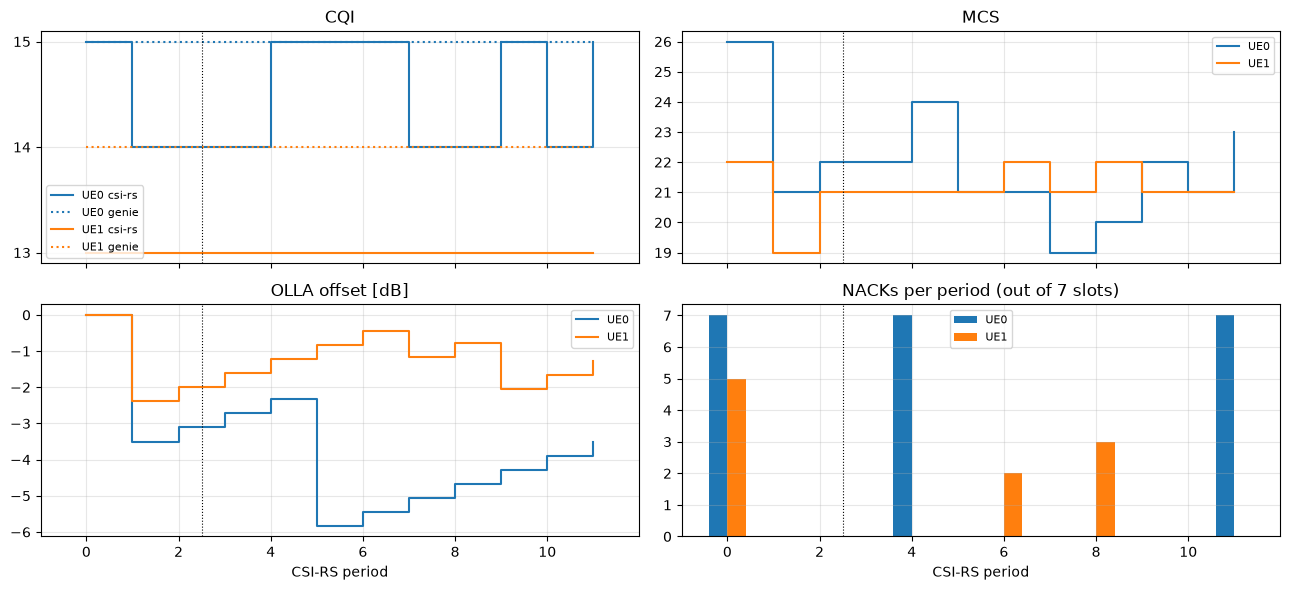

In [14]:
def run_closed_loop(sim_, csi_rx_, num_periods=NUM_PERIODS, slots=SLOTS_PER_PERIOD, seed=SEED):
    sionna_config.seed = seed
    la.reset()
    sim_.reset_stats()
    hist = {k: [] for k in ("cqi", "cqi_genie", "mcs", "offset", "nack", "tbs", "inr")}
    for _ in range(num_periods):
        state_ = make_state(slots, sim_)
        (cqi_g_, _), _ = genie_cqi(sim_, state_)
        if CQI_SOURCE == "csi-rs":
            (cqi_, _), _, diag_ = csirs_cqi(sim_, state_, csi_rx_)
            hist["inr"].append(db(diag_["inr"][0].cpu().numpy()))
        else:
            cqi_ = cqi_g_
        hist["offset"].append(la.offset_db.copy())
        mcs_ = la.select_mcs(cqi_)
        sim_.set_mcs(mcs_)
        st = sim_.run_batch(slots, SNR_RUN, state=state_)
        nack = st.block_errors.astype(int)
        la.update(slots - nack, nack, mcs_)
        for key, v in (("cqi", cqi_), ("cqi_genie", cqi_g_), ("mcs", mcs_), ("nack", nack),
                       ("tbs", np.array(sim_.tb_sizes))):
            hist[key].append(v)
    hist = {k: np.array(v) for k, v in hist.items()}
    m = slice(WARMUP_PERIODS, None)
    n_slots = len(hist["nack"][m]) * slots
    hist["bler"] = hist["nack"][m].sum(0) / n_slots
    hist["tput_mbps"] = ((slots - hist["nack"][m]) * hist["tbs"][m]).sum(0) / n_slots * cfg.slots_per_second / 1e6
    return hist


t0 = time.time()
hist = run_closed_loop(sim, csi_rx)
print(f"{NUM_PERIODS} periods ({NUM_PERIODS * (SLOTS_PER_PERIOD + 1)} slots) in {time.time() - t0:.1f} s; "
      f"the first {WARMUP_PERIODS} periods are excluded from the statistics")
for k in range(NUM_UE):
    print(f"UE{k}: throughput {hist['tput_mbps'][k]:6.1f} Mbps, first-transmission BLER {hist['bler'][k]:.3f}, "
          f"final OLLA offset {hist['offset'][-1, k]:+.2f} dB")

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
x = np.arange(NUM_PERIODS)
for k in range(NUM_UE):
    axes[0, 0].step(x, hist["cqi"][:, k], where="post", color=f"C{k}", label=f"UE{k} {CQI_SOURCE}")
    axes[0, 0].step(x, hist["cqi_genie"][:, k], where="post", color=f"C{k}", ls=":", label=f"UE{k} genie")
    axes[0, 1].step(x, hist["mcs"][:, k], where="post", color=f"C{k}", label=f"UE{k}")
    axes[1, 0].step(x, hist["offset"][:, k], where="post", color=f"C{k}", label=f"UE{k}")
    axes[1, 1].bar(x + 0.4 * k - 0.2, hist["nack"][:, k], width=0.4, color=f"C{k}", label=f"UE{k}")
for ax, t in zip(axes.flat, ["CQI", "MCS", "OLLA offset [dB]", f"NACKs per period (out of {SLOTS_PER_PERIOD} slots)"]):
    ax.set_title(t); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.axvline(WARMUP_PERIODS - 0.5, color="k", ls=":", lw=0.8)
for ax in axes[1]:
    ax.set_xlabel("CSI-RS period")
for ax in (axes[0, 0], axes[0, 1]):
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

## 9. (Optional) Cat A/B × compression on the same drop

With the same channel and the same bits and noise (same seeds), Cat A / Cat B are run in turn with each compression configuration in `COMPARE_WIDTHS` (the Cat B weights use the same bit width as the U-plane).
Three quantities are of interest:

- **Throughput**;
- **OLLA offset**: how far the MAC has to lower the CQI to meet the target BLER, i.e. the part of the distortion that the CSI does not see;
- **ΔCQI = CQI − genie CQI**: how much of the distortion the CSI-RS measurement sees.

Results from a single drop are highly random; for statistical conclusions, run `studies/oran_baseline/rt_compare_compression.py` over many drops.

Cat A ideal 16 bit: mean throughput  195.0 Mbps, BLER 0.056, OLLA offset +0.04 dB, ΔCQI +0.00
Cat A block_scaling  5 bit: mean throughput  166.8 Mbps, BLER 0.079, OLLA offset -2.25 dB, ΔCQI -0.06
Cat A mu_law  5 bit: mean throughput  139.6 Mbps, BLER 0.151, OLLA offset -2.71 dB, ΔCQI -0.72
Cat B ideal 16 bit: mean throughput  195.0 Mbps, BLER 0.056, OLLA offset +0.04 dB, ΔCQI +0.00
Cat B block_scaling  5 bit: mean throughput  164.8 Mbps, BLER 0.111, OLLA offset -1.97 dB, ΔCQI +0.00
Cat B mu_law  5 bit: mean throughput  158.4 Mbps, BLER 0.111, OLLA offset -1.60 dB, ΔCQI -0.44
Elapsed 78.4 s


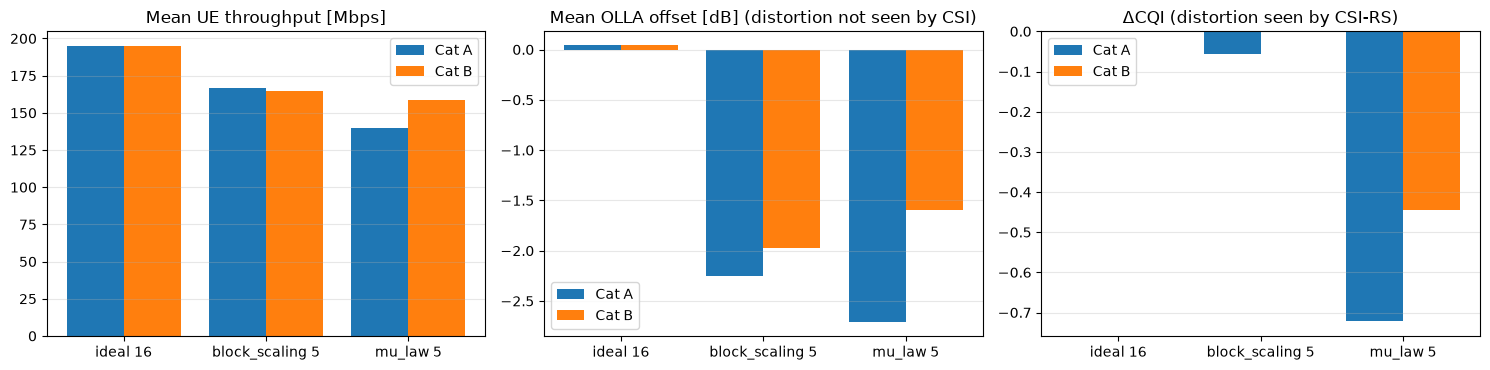

In [15]:
if RUN_COMPARISON:
    results = {}
    t0 = time.time()
    for cat in ("A", "B"):
        cfg_c = replace(cfg, category=cat)
        sim_c = ORANDownlink(cfg_c)
        if CHANNEL_MODEL == "rt":
            sim_c.channel.set_ue_positions(positions)
        csi_rx_c = CSIRSReceiver(csirs, cfg_c.prg_num_prb, sim_c.ue.estimator)
        for comp in COMPARE_WIDTHS:
            sim_c.set_compression(CompressionConfig(*comp), CompressionConfig(*comp))
            h_ = run_closed_loop(sim_c, csi_rx_c)
            results[(cat, comp)] = h_
            m = slice(WARMUP_PERIODS, None)
            dcqi = (h_["cqi"][m] - h_["cqi_genie"][m]).mean()
            print(f"Cat {cat} {comp[0]:>5} {comp[1]:2d} bit: mean throughput {h_['tput_mbps'].mean():6.1f} Mbps, "
                  f"BLER {h_['bler'].mean():.3f}, OLLA offset {h_['offset'][m].mean():+5.2f} dB, ΔCQI {dcqi:+.2f}")
    print(f"Elapsed {time.time() - t0:.1f} s")

    labels = [f"{c[0]} {c[1]}" for c in COMPARE_WIDTHS]
    xs = np.arange(len(COMPARE_WIDTHS))
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    m = slice(WARMUP_PERIODS, None)
    for i, cat in enumerate(("A", "B")):
        hs = [results[(cat, c)] for c in COMPARE_WIDTHS]
        axes[0].bar(xs + 0.4 * i - 0.2, [h_["tput_mbps"].mean() for h_ in hs], 0.4, label=f"Cat {cat}")
        axes[1].bar(xs + 0.4 * i - 0.2, [h_["offset"][m].mean() for h_ in hs], 0.4, label=f"Cat {cat}")
        axes[2].bar(xs + 0.4 * i - 0.2, [(h_["cqi"][m] - h_["cqi_genie"][m]).mean() for h_ in hs], 0.4, label=f"Cat {cat}")
    for ax, t in zip(axes, ["Mean UE throughput [Mbps]", "Mean OLLA offset [dB] (distortion not seen by CSI)", "ΔCQI (distortion seen by CSI-RS)"]):
        ax.set_xticks(xs); ax.set_xticklabels(labels); ax.set_title(t); ax.grid(alpha=0.3, axis="y"); ax.legend()
    plt.tight_layout(); plt.show()

## 10. Summary and further reading

- **What the CSI can see**: zero-valued REs remain zero after compression, so the CSI-IM cannot measure compression distortion. With MU, in Cat A the distortion of the paired UE's CSI-RS leaks into this UE,
  and in Cat B the weight compression degrades the BD nulls; both effects are measured by the NZP-IMR. Self-distortion in the layer domain (Cat B U-plane) can only be absorbed by OLLA.
- **SU vs. MU**: with SU, Cat B is more sensitive to compression, because its layer-domain noise is beamformed together with the signal; with MU, Cat A is more sensitive, because its antenna-domain noise cannot be nulled by BD and leaks to the paired UE.
- **Batch statistics**: `studies/oran_baseline/rt_closed_loop.py` (one configuration, many drops), `studies/oran_baseline/rt_compare_compression.py` (Cat A/B × compression, paired drops, two GPUs in parallel).
- **Design notes and simplifications**: see `oran/README.md`.